# Employee Attrition Prediction

Employee turnover is a major challenge for organizations, as losing employees can increase recruitment costs and affect overall productivity. Understanding the factors associated with employee attrition can help organizations identify potential risks and make better retention decisions.

In this project, exploratory data analysis was performed to identify patterns and factors related to employee attrition. A Logistic Regression model was developed to predict whether an employee is likely to leave the company based on different personal, job-related, and satisfaction features.

Logistic Regression was selected as the main model due to its interpretability, allowing better understanding of how different factors influence the likelihood of employee attrition.

## Project Objective

The main objective is to analyze employee characteristics and build a classification model that predicts employee attrition while identifying the key factors associated with turnover.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/IBM Data.csv")


# 1) Data Understanding


In [2]:
df.shape

(1470, 35)

In [3]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [4]:
df.describe(include = "all")


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470,1470,1470.000000,1470,1470.000000,1470.000000,1470,1470.0,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
unique,NaN,2,3,NaN,3,NaN,NaN,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,No,Travel_Rarely,NaN,Research & Development,NaN,NaN,Life Sciences,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1233,1043,NaN,961,NaN,NaN,606,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,36.923810,NaN,NaN,802.485714,NaN,9.192517,2.912925,NaN,1.0,1024.865306,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,NaN,NaN,403.509100,NaN,8.106864,1.024165,NaN,0.0,602.024335,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,NaN,NaN,102.000000,NaN,1.000000,1.000000,NaN,1.0,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,NaN,NaN,465.000000,NaN,2.000000,2.000000,NaN,1.0,491.250000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,NaN,NaN,802.000000,NaN,7.000000,3.000000,NaN,1.0,1020.500000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,NaN,NaN,1157.000000,NaN,14.000000,4.000000,NaN,1.0,1555.750000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [6]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# 2) Data Cleaning


In [7]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Attrition"]=df["Attrition"].map({"No": 0,"Yes": 1})

In [10]:
from sklearn.preprocessing import OneHotEncoder

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = encoder.fit_transform(df[categorical_cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=df.index
)

df = df.drop(columns=categorical_cols)
df = pd.concat([df, encoded_df], axis=1)

/var/folders/wc/vn6dzgy15mjfz5q2f7hysdkr0000gn/T/ipykernel_85628/3723294938.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


# Exploratory Data Analysis (EDA)


In [11]:
for prefix in[
    "Gender",
    "Department",
    "BusinessTravel",
    "OverTime",
    "MaritalStatus",
    "EducationField",
    "JobRole"]:
    X = df.drop(columns=["Attrition"])
    cols = [c for c in X.columns if c.startswith(prefix + "_")]
    print(f"\n{prefix}: {cols}")


Gender: ['Gender_Female', 'Gender_Male']

Department: ['Department_Human Resources', 'Department_Research & Development', 'Department_Sales']

BusinessTravel: ['BusinessTravel_Non-Travel', 'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely']

OverTime: ['OverTime_No', 'OverTime_Yes']

MaritalStatus: ['MaritalStatus_Divorced', 'MaritalStatus_Married', 'MaritalStatus_Single']

EducationField: ['EducationField_Human Resources', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree']

JobRole: ['JobRole_Healthcare Representative', 'JobRole_Human Resources', 'JobRole_Laboratory Technician', 'JobRole_Manager', 'JobRole_Manufacturing Director', 'JobRole_Research Director', 'JobRole_Research Scientist', 'JobRole_Sales Executive', 'JobRole_Sales Representative']


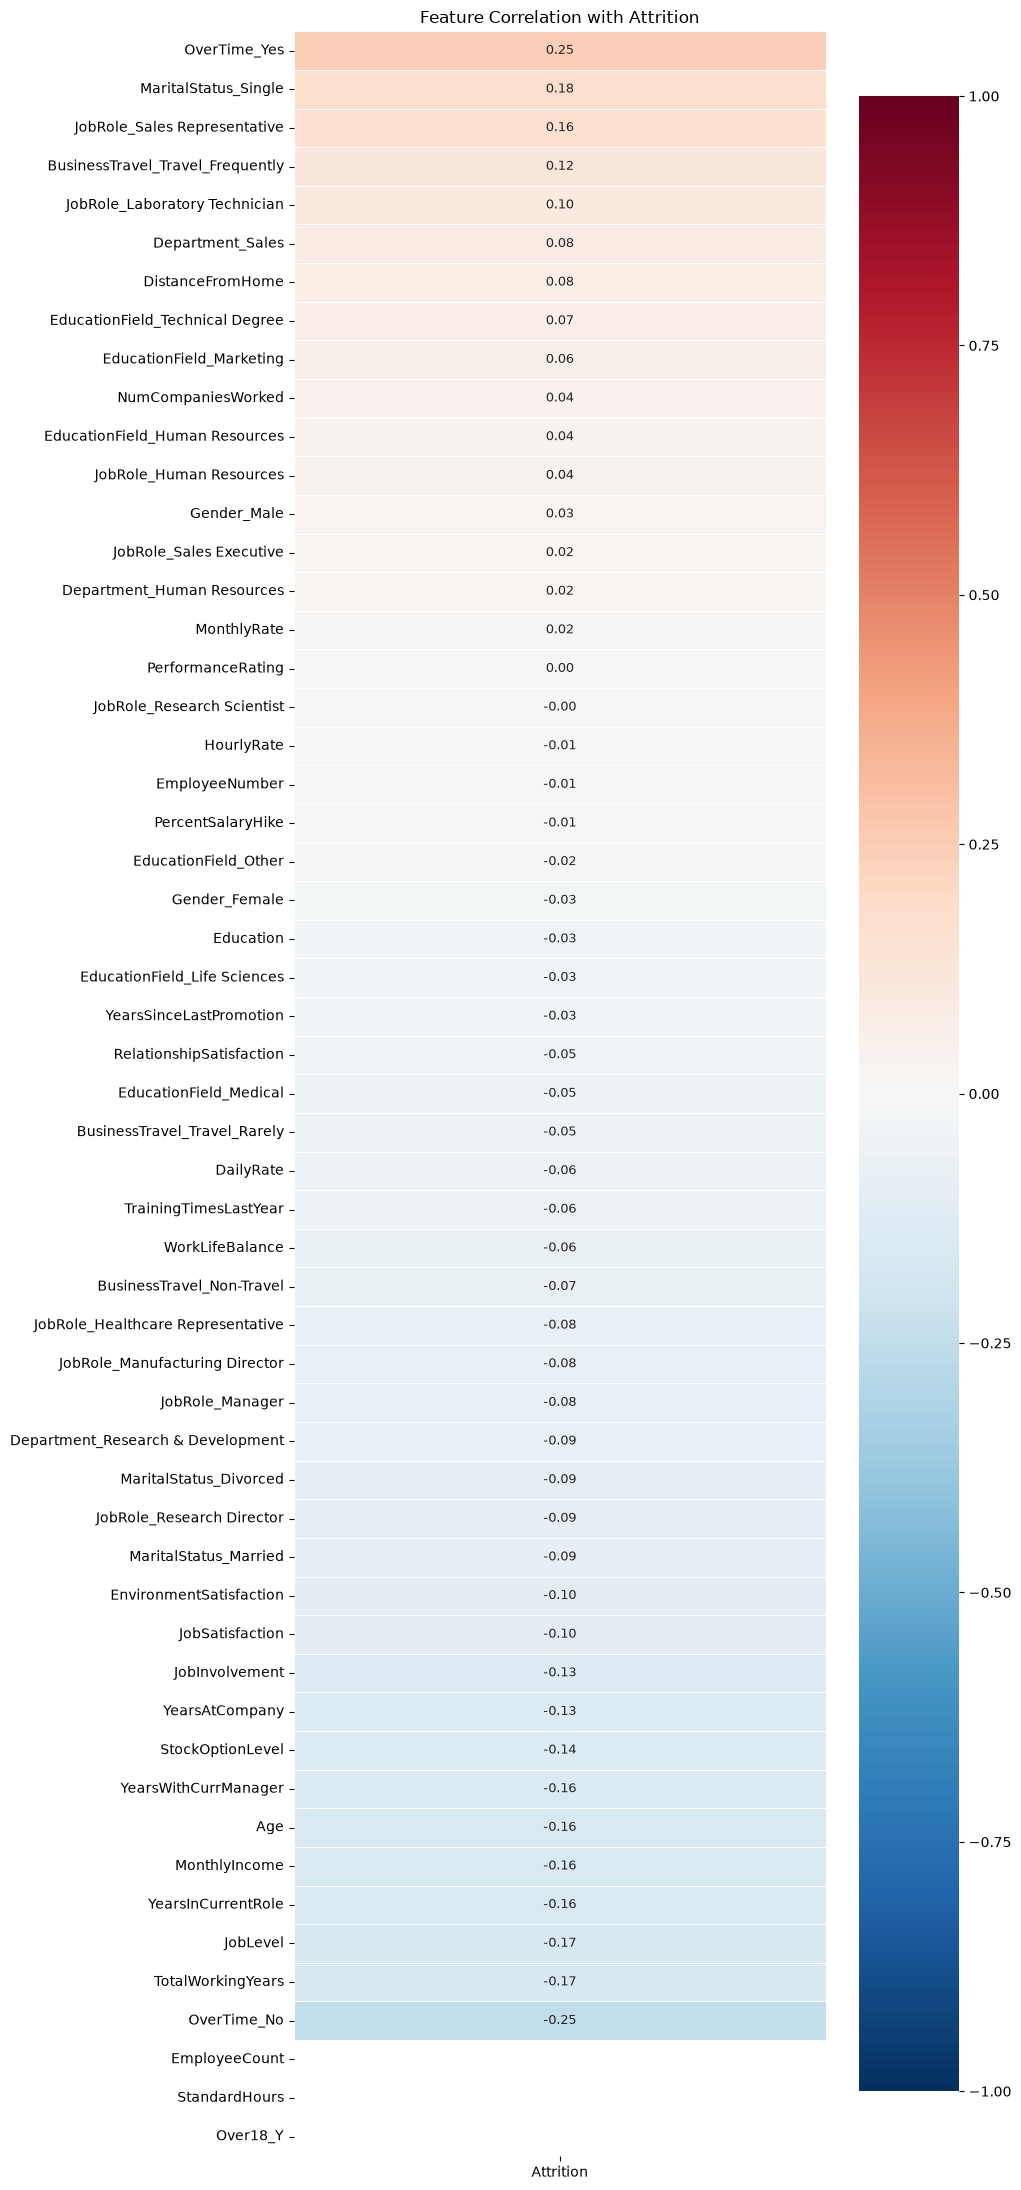

In [12]:
corr = (
    df.corr(numeric_only=True)["Attrition"]
    .drop("Attrition")
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, max(12, len(corr) * 0.4)))

sns.heatmap(
    corr.to_frame(),
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 9}
)

plt.title("Feature Correlation with Attrition")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

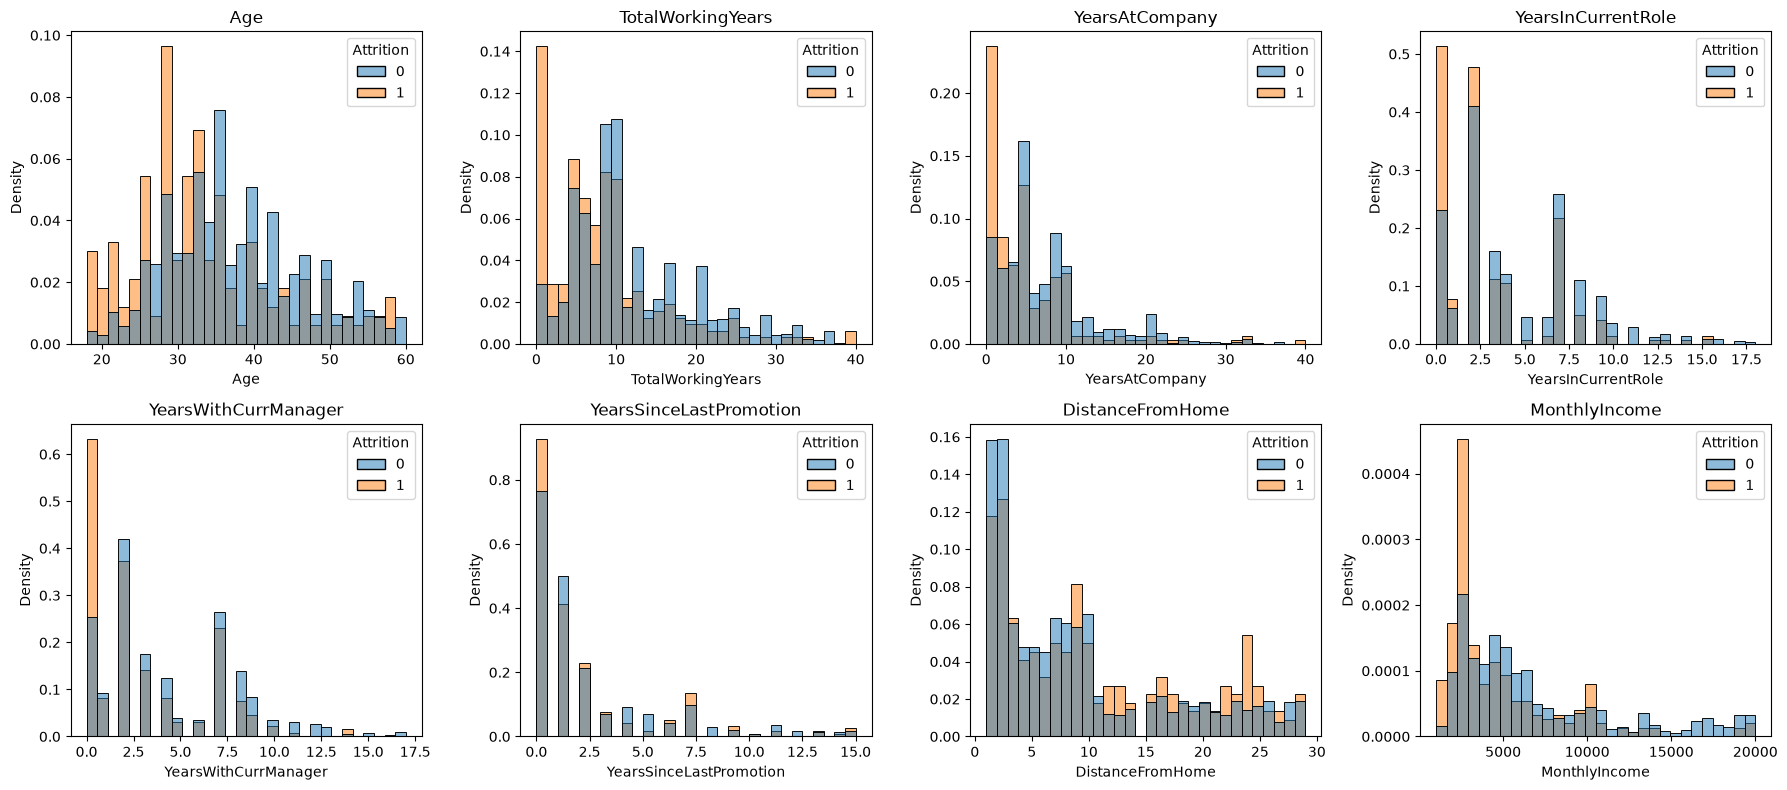

In [13]:
cols = [
    "Age",
    "TotalWorkingYears",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "YearsSinceLastPromotion",
    "DistanceFromHome",
    "MonthlyIncome"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cols):
    sns.histplot(
        data=df,
        x=col,
        hue="Attrition",
        bins=30,
        multiple="layer",
        stat="density",
        common_norm=False,
        ax=ax)
    ax.set_title(col)



plt.tight_layout()
plt.show()

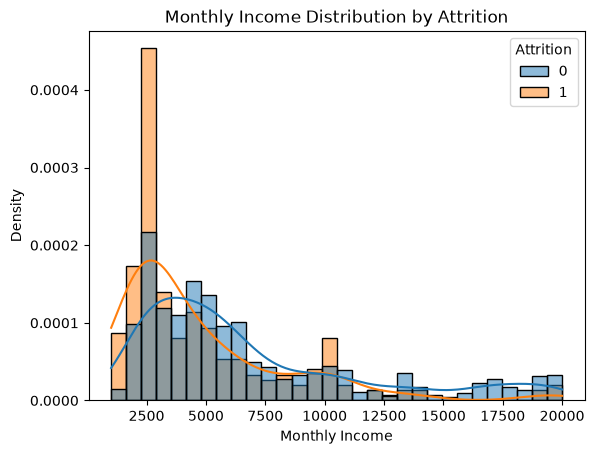

In [14]:
sns.histplot(
    data=df,
    x="MonthlyIncome",
    hue="Attrition",
    kde=True,
    bins=30,
    stat="density",
    common_norm=False)

plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Monthly Income")
plt.show()

### EDA Observations

- Employees who left are more concentrated at lower tenure levels, although attrition occurs across different experience levels.
- A noticeable concentration of employees who left appears around a monthly income of 2,500.
- `DistanceFromHome` shows no clear visual difference between employees who left and those who stayed.

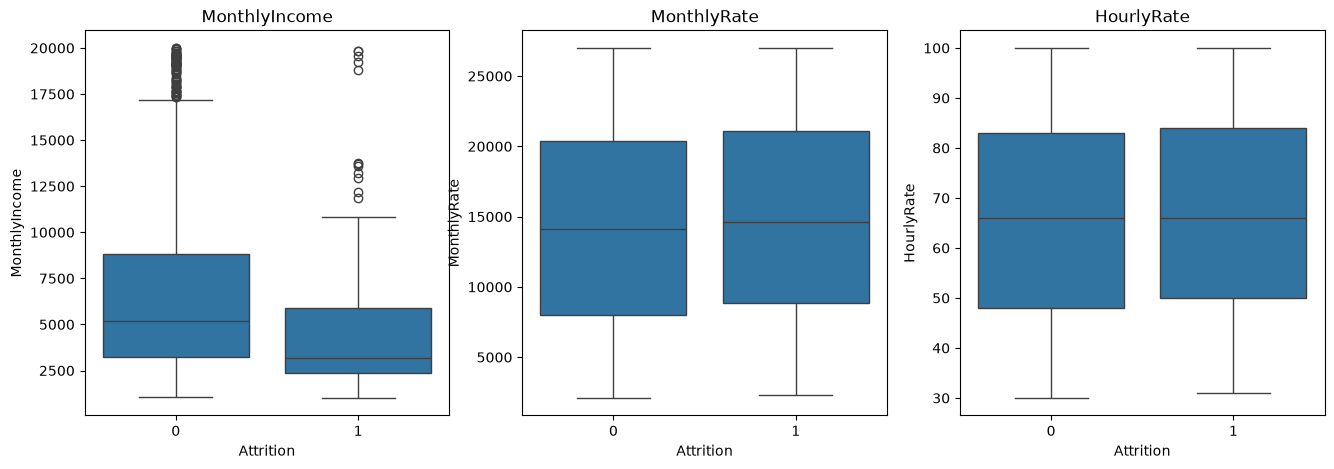

In [15]:
cols = ["MonthlyIncome", "MonthlyRate","HourlyRate"]
fig,axes=plt.subplots(1,3,figsize=(16,5))

for ax, col in zip(axes, cols):
    sns.boxplot(
        data=df,
        x="Attrition",
        y=col,
        ax=ax)
    ax.set_title(col)
plt.show()



Monthly Income showed a clearer difference between employees who left and stayed compared to Monthly Rate and Hourly Rate, indicating that income level may have a stronger association with employee attrition.

### Additional Attrition Factors

Single employees had the highest attrition rate despite not being the largest group. In addition, frequent business travelers showed higher attrition rates, suggesting a possible relationship between these factors and employee turnover.

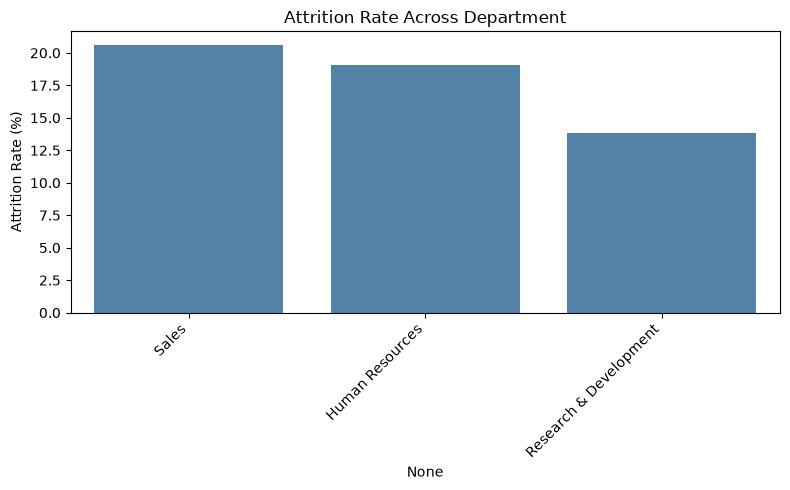

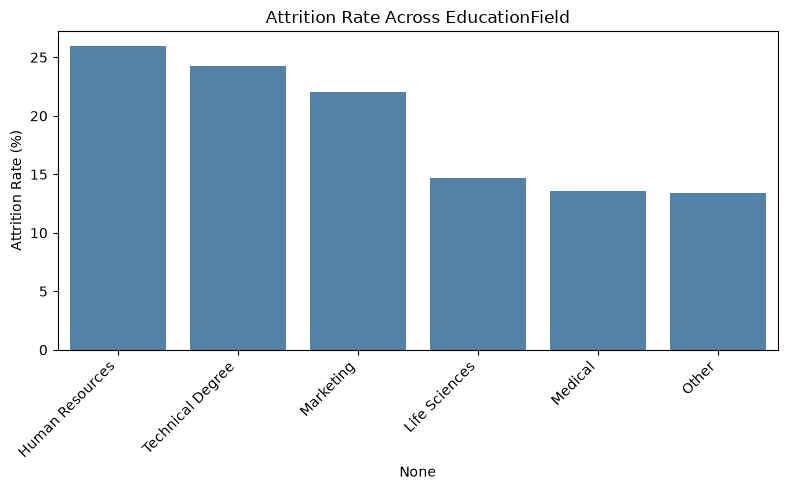

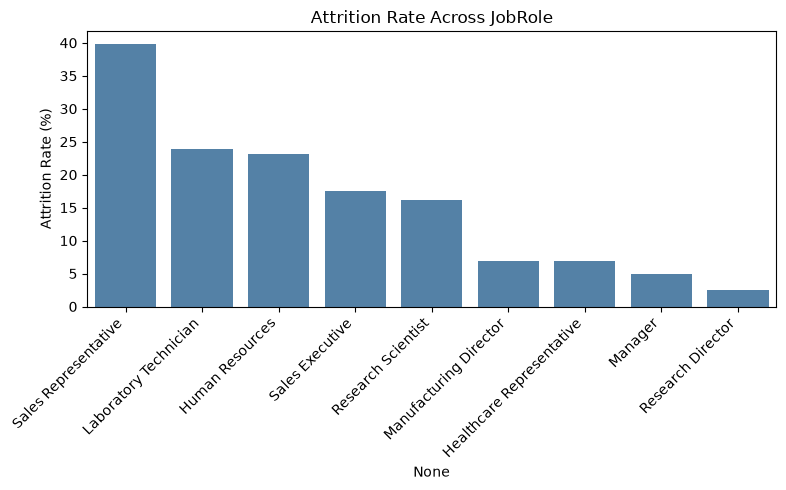

In [16]:
cat_cols = ["Department", "EducationField", "JobRole"]

for col in cat_cols:
    cols = [c for c in df.columns if c.startswith(col + "_")]
    rate = {
        c.replace(col + "_", ""): df.loc[df[c] == 1, "Attrition"].mean() * 100
        for c in cols}

    rate = pd.Series(rate).sort_values(ascending=False)

    plt.figure(figsize=(8, 5))
    sns.barplot(x=rate.index, y=rate.values, color="steelblue")
    plt.title(f"Attrition Rate Across {col}")
    plt.ylabel("Attrition Rate (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

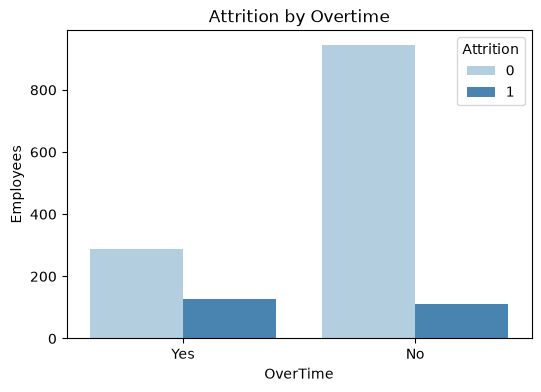

In [17]:
df_plot = df.copy()

df_plot["OverTime"] = df_plot["OverTime_Yes"].map({
    1: "Yes",
    0: "No"
})

plt.figure(figsize=(6,4))

sns.countplot(
    data=df_plot,
    x="OverTime",
    hue="Attrition",
    palette="Blues"
)

plt.title("Attrition by Overtime")
plt.xlabel("OverTime")
plt.ylabel("Employees")
plt.show()

In [18]:
satisfaction_cols = [
    "EnvironmentSatisfaction",
    "JobSatisfaction",
    "RelationshipSatisfaction",
    "WorkLifeBalance"]
df.groupby("Attrition")[satisfaction_cols].mean().round(2)

,EnvironmentSatisfaction,JobSatisfaction,RelationshipSatisfaction,WorkLifeBalance
Attrition,,,,
0,2.77,2.78,2.73,2.78
1,2.46,2.47,2.60,2.66


### Key Findings

Job Satisfaction and Environment Satisfaction had the largest gap between stayed and left employees, suggesting a stronger association with attrition. Overtime also showed a clear relationship with employee turnover, with higher attrition among employees working overtime.

# 3) Baseline Model

In [19]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import *
import pandas as pd

X = df.drop(columns="Attrition")
y =df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

models = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "Extra Trees": ExtraTreesClassifier(class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC(class_weight="balanced", probability=True))}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    results.append([name, precision_score(y_test, pred), recall_score(y_test, pred),
                    f1_score(y_test, pred), roc_auc_score(y_test, p)])

pd.DataFrame(results, columns=["Model", "Precision", "Recall", "F1", "ROC-AUC"]).round(3)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Precision,Recall,F1,ROC-AUC
0,Logistic,0.368,0.690,0.480,0.813
1,Decision Tree,0.290,0.254,0.271,0.567
2,Random Forest,0.453,0.338,0.387,0.784
3,Extra Trees,0.688,0.155,0.253,0.785
4,Gradient Boosting,0.517,0.211,0.300,0.784
5,SVM,0.581,0.254,0.353,0.789


### Model Selection

We selected **Logistic Regression** because it achieved the highest Recall (0.690) and F1-score (0.480) among the tested models, making it the best fit for our objective.

In [20]:
df_base = df.copy()
df_fe = df.copy()
x=df_base.drop(columns="Attrition")
y=df_base["Attrition"]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.7,random_state=42,stratify=y)

In [21]:
from sklearn.metrics import classification_report, accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline_model = make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000, random_state=42))

baseline_model.fit(x_train, y_train)

baseline_pred = baseline_model.predict(x_test)
train_pred = baseline_model.predict(x_train)

print("Train")
print(classification_report(y_train, train_pred))

print("Test")
print(classification_report(y_test, baseline_pred))

Train
              precision    recall  f1-score   support

           0       0.91      0.97      0.94       863
           1       0.78      0.49      0.60       166

    accuracy                           0.90      1029
   macro avg       0.84      0.73      0.77      1029
weighted avg       0.89      0.90      0.88      1029

Test
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       370
           1       0.71      0.41      0.52        71

    accuracy                           0.88       441
   macro avg       0.80      0.69      0.72       441
weighted avg       0.86      0.88      0.86       441



# 4) Feature Engineering

In [22]:
df_fe["Under20"] = np.where(df_fe["Age"] <=20, 1, 0)

In [23]:
df_fe["LowWorkExperience"] = np.where(df_fe["TotalWorkingYears"] ==0 , 1, 0)

In [24]:
df_fe["lowIncome"] = np.where(df_fe["MonthlyIncome"] <=2750, 1, 0)

In [25]:
df_fe["RoleStagnation"] = (df_fe["YearsInCurrentRole"] /(df_fe["YearsAtCompany"] + 1)) 
df_fe["PromotionRate"] = (df_fe["YearsAtCompany"] /(df_fe["YearsSinceLastPromotion"] + 1))

In [26]:
df_fe = df_fe.drop(columns=["EmployeeCount","StandardHours","EmployeeNumber","Over18","HourlyRate","Education"], errors="ignore")


# 6) Modeling

In [27]:
df_without_fe = df.copy()
df_with_fe = df_fe.copy()

In [33]:
from sklearn.pipeline import Pipeline
X = df_with_fe.drop(columns="Attrition")
y = df_with_fe["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42, stratify=y)

model = Pipeline([("scaler", StandardScaler()),("logistic", LogisticRegression(max_iter=5000,class_weight="balanced"))])

model.fit(X_train, y_train)
train_pred = (model.predict_proba(X_train)[:, 1] >= 0.35).astype(int)
test_pred = (model.predict_proba(X_test)[:, 1] >= 0.35).astype(int)

print("train")
print(classification_report(y_train, train_pred))
print("test")
print(classification_report(y_test, test_pred))

train
              precision    recall  f1-score   support

           0       0.97      0.68      0.80       863
           1       0.35      0.88      0.50       166

    accuracy                           0.71      1029
   macro avg       0.66      0.78      0.65      1029
weighted avg       0.87      0.71      0.75      1029

test
              precision    recall  f1-score   support

           0       0.96      0.69      0.80       370
           1       0.34      0.85      0.49        71

    accuracy                           0.72       441
   macro avg       0.65      0.77      0.65       441
weighted avg       0.86      0.72      0.75       441



### Model: Logistic Regression

**Model Configuration**
- Applied `StandardScaler` to standardize numerical features.
- Set `class_weight="balanced"` to address class imbalance.
- Increased `max_iter` to 5000 to ensure convergence.
- Adjusted the classification threshold to 0.35 to improve minority-class detection.

**Feature Engineering**
- Added engineered features to capture additional employee patterns.
- Evaluated the impact of feature engineering by comparing performance before and after adding the selected features.
- Kept the same Logistic Regression configuration and classification threshold (0.35) to ensure a fair comparison.

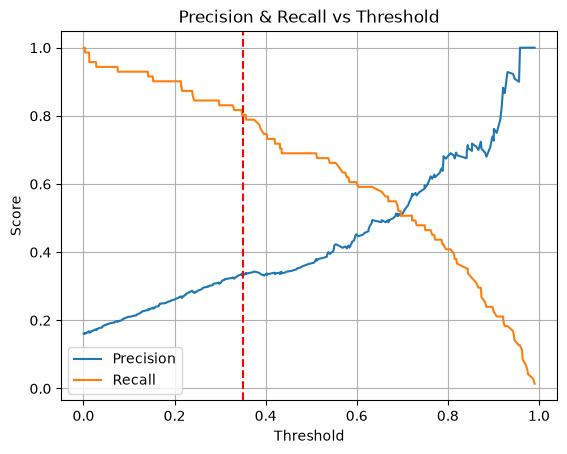

In [29]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

X = df_without_fe.drop(columns="Attrition")
y = df_without_fe["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=42, stratify=y)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=5000, class_weight="balanced"))])

model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
p, r, thresholds = precision_recall_curve(y_test, proba)

plt.plot(thresholds, p[:-1], label="Precision")
plt.plot(thresholds, r[:-1], label="Recall")
plt.axvline(0.35, color="red", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision & Recall vs Threshold")
plt.legend()
plt.grid()
plt.show()

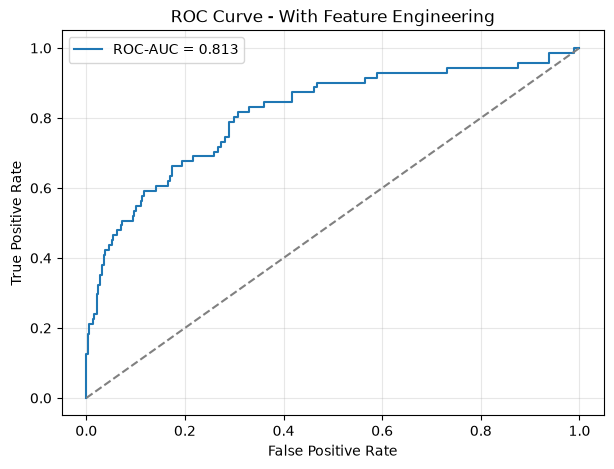

ROC-AUC: 0.8131


In [30]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr_fe, tpr_fe, _ = roc_curve(y_test, proba)
auc_fe = roc_auc_score(y_test, proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr_fe, tpr_fe, label=f"ROC-AUC = {auc_fe:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - With Feature Engineering")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("ROC-AUC:", round(auc_fe, 4))

### Conclusion

Feature Engineering improved the model's ability to identify employees at risk of leaving, achieving a Recall of **0.85**. Although Precision was 0.34, this trade-off is acceptable for our objective, as the company can follow up with employees identified as at risk. Missing an employee who may leave could be more costly than conducting additional follow-up assessments.